![Banner](images/09_distributed_spatial_datas.png)

# From a Laptop to a Cluster: Sessions, Workers and the Dashboard

Notebook 00 ran everything on Dask's threaded scheduler, which uses every core of one machine
inside one Python process. That is the right default for NumPy and GDAL work, but not always
enough: pure Python code is held back by the global interpreter lock, one process cannot use a
second machine, and a GPU wants a worker of its own. A **Dask cluster** solves all three: a
scheduler hands tasks to worker processes on this machine, on GPUs or on the nodes of an HPC
system or a Kubernetes cluster. This notebook starts and stops clusters with `pdist.start`,
compares threads and processes on two kinds of work, shows the dashboard and the job scripts that
HPC clusters run, and measures the two decisions that matter most for raster work: chunk size,
and when to keep data in worker memory with `persist`.

## Overview

### The parts of a Dask cluster

| Part | Role |
|---|---|
| **Client** | your Python session; builds task graphs and submits them |
| **Scheduler** | one process that tracks every task and decides which worker runs it, preferring the worker that already holds its inputs |
| **Workers** | processes that run tasks with a pool of threads, hold results in memory and send them to each other when needed |
| **Nanny** | a small process per worker that restarts it if it dies or exceeds its memory limit |

With no cluster, Dask's **threaded scheduler** runs the graph with a thread pool inside your own
process: no scheduler, no copies, no network, but also no isolation and only one machine.

### Threads or processes

Python's **global interpreter lock (GIL)** lets only one thread run Python bytecode at a time.
Compiled libraries (NumPy, SciPy, GDAL, Shapely 2, CuPy) release it during their inner loops, so
threads run them in parallel. Code that loops in Python (a `for` loop over features, a function
applied row by row) does not, and only separate **processes** run it in parallel. Processes pay
for that: data crossing between them are serialized and copied.

| Work | Best choice |
|---|---|
| NumPy, SciPy, GDAL and rasterio, Shapely 2 vectorized operations | threads (or few processes with many threads) |
| pure Python loops, GeoPandas `apply`, many small objects | processes with one or two threads each |
| GPU work | one worker process per GPU (`dask-cuda`) |
| more memory or cores than one machine has | a cluster on several machines (HPC or cloud) |

### Memory limits and spilling

Each worker has a memory limit. Above 60 % of it the worker writes (spills) results to disk,
above 80 % it pauses, and at 95 % the nanny restarts it. Spilling keeps large jobs alive but slow;
a job that spills constantly needs smaller chunks, more workers or `persist` used more carefully.

### Chunk size

Every chunk is at least one task, and every task costs the scheduler roughly a millisecond of
overhead plus a little memory. Tiny chunks drown the work in overhead; huge chunks leave cores
idle and risk running out of memory. Dask's guidance is chunks of about 100 MB; for moving windows
the chunk must also be much wider than the halo.

## Sessions with GeoLattice

`pdist.start(kind, ...)` starts or connects to a cluster, makes it the active session (every lazy
operation in `geolattice.distributed` then runs on it) and returns a `Session`:

| `kind` | What starts | Extra arguments |
|---|---|---|
| `"local"` | worker processes on this machine | `n_workers`, `threads_per_worker`, `memory_limit` |
| `"cuda"` | one worker per GPU with `dask-cuda` | `rmm_pool_size`, `device_memory_limit`, ... |
| `"auto"` | `"cuda"` if a GPU and dask-cuda exist, else `"local"` | |
| `"slurm"`, `"pbs"` | batch jobs that run workers, with `dask-jobqueue` | `cores`, `memory`, `walltime`, `queue`, `account` |
| `"kubernetes"` | worker pods with the `dask-kubernetes` operator | `image`, `resources`, ... |
| `"address"` | connect to a scheduler that is already running | `address="tcp://host:8786"` |

| `Session` member | Use |
|---|---|
| `status()` | workers, threads, total memory, dashboard link |
| `dashboard_link` | the live dashboard (task stream, memory, progress) |
| `scale(n)`, `adapt(minimum, maximum)` | fixed or load-driven number of workers |
| `client`, `cluster` | the underlying Dask objects |
| `close()` or `with pdist.start(...) as s:` | shut down |

`pdist.status()` and `pdist.dashboard_link()` describe the active session, and
`pdist.plan_chunks`, `pdist.persist` and `pdist.compute` help with chunking and memory.

### Learning objectives

1. Describe the client, scheduler, workers and nanny, and when Dask runs without them.
2. Choose threads or processes for a workload, and measure the difference.
3. Start, scale and close local and GPU clusters, and connect to a running scheduler.
4. Read the job script a SLURM or PBS cluster submits, and know what changes on Kubernetes.
5. Choose a raster chunk size from measurements and from `pdist.plan_chunks`.
6. Use `persist` for data that several computations reuse, and avoid pulling large results to the
   client.
7. Write a cluster script with the `if __name__ == "__main__":` guard.

### Data

| Dataset | Content |
|---|---|
| Great Plains elevation | 90 m DEM, 17,196 x 15,245 pixels, from `Data/03_spatial_analysis/Great_plain/Raster/elev.tif` |
| Kansas building footprints | 1.6 million polygons cached by `dd.kansas_buildings()` (notebook 00) |

### Contents

- Setup
- The default: threads in this process
- A local cluster
- Threads or processes
- Scaling a cluster
- One worker per GPU
- HPC and cloud clusters
- Connecting to a running scheduler
- Choosing a chunk size
- Persist, compute and pulling results
- A cluster script
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import re  # text substitution for printed job scripts
import subprocess  # run the example script
import sys  # the current Python interpreter
import dask  # Dask configuration

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)


## The default: threads in this process

Without a session, `pdist.status()` reports Dask's threaded scheduler: one "worker" (this
process) with one thread per core.

This machine has a GPU, so `compute="auto"` would put the slope chunks on it. The comparisons of
threads, processes and chunk sizes below pass `compute="cpu"` so that they measure the CPU; the
GPU worker gets its own section.

In [2]:
print(pdist.status())  # no session yet
dem = dd.gp_raster("elev")  # lazy DEM, 2048 x 2048 chunks
with dd.timer("mean slope, threaded scheduler"):  # time it
    print(f"mean slope {float(pdist.raster.slope(dem, compute='cpu').mean()):.3f} degrees")  # read, slope, reduce

{'kind': 'threads', 'workers': 1, 'threads': 24, 'dashboard': None}


mean slope 4.484 degrees
mean slope, threaded scheduler: 2.30 s


## A local cluster

`pdist.start("local")` starts a scheduler and worker processes on this machine. Here 4 workers
with 6 threads each use the 24 cores, each limited to 24 GB of memory.

In [3]:
s = pdist.start("local", n_workers=4, threads_per_worker=6, memory_limit="24GB")  # start the cluster
print(s)  # session and dashboard
st = s.status()  # workers, threads, memory
print({k: (dd.gb(v) if k == "memory_limit" else v) for k, v in st.items()})  # readable
print("active session:", pdist.get_session() is s)  # every lazy operation now runs here

<Session kind='local' dashboard='http://127.0.0.1:8787/status'>
{'kind': 'local', 'workers': 4, 'threads': 24, 'memory_limit': '96.00 GB', 'dashboard': 'http://127.0.0.1:8787/status'}
active session: True


In [4]:
with dd.timer("mean slope, local cluster (4 processes x 6 threads)"):  # same computation on the cluster
    print(f"mean slope {float(pdist.raster.slope(dem, compute='cpu').mean()):.3f} degrees")  # identical result

mean slope 4.484 degrees
mean slope, local cluster (4 processes x 6 threads): 3.90 s


The result is identical, but the cluster was slower than plain threads. This workload is NumPy,
which already ran in parallel on threads inside one process; on the cluster, the halo strips that
neighbouring chunks exchange travel between processes, and every task goes through the scheduler.
For NumPy and GDAL work on one machine the threaded scheduler is usually the fastest choice; the
cluster pays off with code that holds the GIL (next section), with several machines, and when
isolation and the dashboard matter. The dashboard link above opens a live view of the task stream,
worker memory and progress bars; on a remote machine forward port 8787 with
`ssh -L 8787:localhost:8787 host`.

## Threads or processes

The difference appears with pure Python code. The function below computes building areas with a
Python loop over the vertices (the shoelace formula), as hand-written per-feature code often does.
It runs on 24 partitions of 400,000 buildings three ways: the threaded scheduler, the local
cluster's processes, and, for comparison, the vectorized `pdist.vector.area` (Shapely releases the
GIL).

In [5]:
def shoelace_area(part):  # pure Python: one loop per building, one per vertex
    out = []  # areas
    for g in part.geometry:  # each polygon
        xy = list(g.exterior.coords)  # its vertices as Python tuples
        a = 0.0  # running sum
        for (x0, y0), (x1, y1) in zip(xy[:-1], xy[1:]):  # each edge
            a += x0 * y1 - x1 * y0  # shoelace term
        out.append(abs(a) / 2)  # polygon area
    return pd.Series(out, index=part.index)  # aligned to the input


bld = dd.kansas_buildings().iloc[:400_000].to_crs(5070)  # 400,000 buildings in metres
parts = pdist.spatial_partition(bld, 24, method="none")  # 24 slices of rows
tasks = [dask.delayed(shoelace_area)(p) for p in parts]  # one task per slice
res = {}  # seconds per way
with dask.config.set(scheduler="threads"):  # ignore the cluster: threads in this process
    with dd.timer("pure Python, 24 threads (GIL)", res):  # time it
        a_thr = pd.concat(dask.compute(*tasks))  # run
with dd.timer("pure Python, 4 processes x 6 threads", res):  # the cluster
    a_proc = pd.concat(dask.compute(*tasks))  # run on workers

pure Python, 24 threads (GIL): 3.81 s


pure Python, 4 processes x 6 threads: 2.32 s


In [6]:
s.close()  # close the 4 x 6 cluster
s = pdist.start("local", n_workers=24, threads_per_worker=1, memory_limit="4GB")  # one thread per process
s.client.wait_for_workers(24)  # wait until all have started
with dd.timer("pure Python, 24 processes x 1 thread", res):  # one Python interpreter per core
    a_p24 = pd.concat(dask.compute(*tasks))  # run
with dask.config.set(scheduler="threads"):  # back to threads for the vectorized version
    with dd.timer("Shapely vectorized, 24 threads", res):  # compiled code releases the GIL
        a_vec = pdist.vector.area(bld)  # GEOS area
print("largest difference between methods:", float((a_p24 - a_vec).abs().max()), "m2")  # same answer
pd.Series(res, name="seconds").round(2).to_frame()  # table

pure Python, 24 processes x 1 thread: 2.02 s
Shapely vectorized, 24 threads: 0.08 s
largest difference between methods: 0.0003866876122629037 m2


,seconds
"pure Python, 24 threads (GIL)",3.81
"pure Python, 4 processes x 6 threads",2.32
"pure Python, 24 processes x 1 thread",2.02
"Shapely vectorized, 24 threads",0.08


On threads the Python loop gains little from 24 cores, because the GIL lets one thread run
Python at a time. Four processes with six threads each were nearly twice as fast, and 24
single-threaded processes a little faster again, because each process has its own interpreter
and its own GIL. The gain is far below 24-fold: every partition of polygons has to be pickled,
sent to a worker process and unpickled there, and the areas sent back. The real lesson is in the
last row: the vectorized Shapely call, which runs in C and releases the GIL, was about
twenty-five times faster than the best of them. **Vectorize first; reach for processes only for code that
cannot be vectorized.**

## Scaling a cluster

`scale(n)` sets a fixed number of workers; `adapt(minimum, maximum)` adds workers while tasks are
waiting and retires idle ones, which on a shared HPC system releases nodes as soon as they are
not needed.

In [7]:
s.scale(8); s.client.wait_for_workers(8); time.sleep(2)  # shrink to 8 workers
print("after scale(8):", s.status()["workers"], "workers")  # check
s.adapt(minimum=2, maximum=12)  # let load decide between 2 and 12
print("adaptive between 2 and 12 workers; now", s.status()["workers"])  # adaptive mode
s.close()  # shut down
print("after close:", pdist.status()["kind"])  # back to threads

after scale(8): 8 workers
adaptive between 2 and 12 workers; now 8


after close: threads


## One worker per GPU

`pdist.start("cuda")` uses dask-cuda's `LocalCUDACluster`: one worker process per visible GPU,
each pinned to its device. Arguments such as `rmm_pool_size="8GB"` give each worker an RMM memory
pool, and `device_memory_limit` makes the worker spill GPU data to host memory before the device
fills up. Inside the session, `compute="gpu"` operations run on the GPU worker.

In [8]:
if caps["gpus"]:  # needs a GPU and dask-cuda
    with pdist.start("cuda") as g:  # one worker per GPU, closed at the end of the block
        print(g, g.status()["workers"], "worker(s), GPU session:", g.is_gpu)  # one worker here
        with dd.timer("mean slope on the GPU worker (read on the worker, slope on its GPU)"):  # time it
            v = float(pdist.raster.slope(dem, compute="gpu").mean())  # chunks become CuPy on the worker
        print(f"mean slope {v:.3f} degrees")  # same answer
else:  # without a GPU
    print("no GPU: pdist.start('auto') would start a CPU cluster instead")  # fallback

<Session kind='cuda' dashboard='http://127.0.0.1:8787/status'> 1 worker(s), GPU session: True


mean slope on the GPU worker (read on the worker, slope on its GPU): 5.61 s
mean slope 4.484 degrees


With one GPU the GPU worker has one thread, so it reads and decodes the GeoTIFF chunks one after
another; the CPU sessions read them on 24 threads. That is why the whole chain (read, copy to the
GPU, slope, reduce) was several times slower here than on the CPU, even though slope itself is
much faster on the GPU (notebook 00). For a GPU pipeline the reading has to keep up: data already
in GPU memory, a faster format (notebook 02) or several CPU threads feeding the device. On a
machine with several GPUs `pdist.start("cuda")` starts one worker per device and the chunks are
shared between them; here, with one, the same code runs on one.

## HPC and cloud clusters

On an HPC system the workers run inside batch jobs. `pdist.start("slurm", ...)` creates a
`dask_jobqueue.SLURMCluster`: the scheduler runs where you are (a login node or a small job), and
each worker is an `sbatch` job. Starting the session without `n_workers` submits nothing, so the
job script it would submit can be read on any machine. The scheduler address is replaced by
`<scheduler>` in the printout.

In [9]:
hpc = pdist.start("slurm", cores=24, processes=4, memory="96GB", walltime="02:00:00",  # one job = 4 workers x 6 threads
                  queue="normal", account="my_project",  # partition and allocation
                  job_extra_directives=["--constraint=intel"])  # any extra #SBATCH line
print(re.sub(r"tcp://\S+", "tcp://<scheduler>", hpc.cluster.job_script()))  # the script sbatch would receive
print("workers now:", hpc.status()["workers"], "(nothing submitted)")  # no job until scale()
hpc.close()  # stop the local scheduler

#!/usr/bin/env bash

#SBATCH -J dask-worker
#SBATCH -p normal
#SBATCH -A my_project
#SBATCH -n 1
#SBATCH --cpus-per-task=24
#SBATCH --mem=90G
#SBATCH -t 02:00:00
#SBATCH --constraint=intel

/home/zia207/.pyenv/versions/3.11.16/bin/python3 -m distributed.cli.dask_worker tcp://<scheduler> --name dummy-name --nthreads 6 --memory-limit 22.35GiB --nworkers 4 --nanny --death-timeout 60

workers now: 0 (nothing submitted)


On a real cluster, `hpc.scale(jobs=10)` (or `pdist.start("slurm", n_workers=10, ...)`) would
submit ten such jobs and `hpc.adapt(maximum_jobs=50)` would let the load decide. `kind="pbs"`
writes the same with `#PBS` directives. Two practical rules: keep `cores` and `memory` equal to
what one job really gets, and use `processes=` to split a job into several workers when the work
holds the GIL.

On Kubernetes, `pdist.start("kubernetes", image="ghcr.io/dask/dask:latest", n_workers=10,
resources={"requests": {"memory": "8Gi"}})` asks the dask-kubernetes operator for a scheduler pod
and ten worker pods. The image must contain the same Python packages (GeoLattice included) as the
client. This cannot run on the build machine, which has no Kubernetes cluster, so the call is
shown, not executed.

## Connecting to a running scheduler

A scheduler can also be started outside Python (`dask scheduler` and `dask worker` on the command
line, a Helm chart, a cloud service). `pdist.start("address", address=...)` connects to it. Here a
small cluster stands in for such a service.

In [10]:
from dask.distributed import LocalCluster  # stand-in for a cluster started elsewhere

service = LocalCluster(n_workers=2, threads_per_worker=2, dashboard_address=None)  # "someone else's" cluster
s = pdist.start("address", address=service.scheduler_address)  # connect by address
print(s.kind, s.status()["workers"], "workers,", s.status()["threads"], "threads")  # what we joined
try:  # a session by address does not own the cluster
    s.scale(4)  # not allowed
except RuntimeError as e:  # expected
    print("scale():", e)  # message
s.close(); service.close()  # disconnect, then stop the stand-in

address 2 workers, 4 threads
scale(): Cannot scale a cluster this session did not create


## Choosing a chunk size

`pdist.plan_chunks(shape, dtype)` proposes square chunks of about 128 MB for the CPU, or about 5 %
of free GPU memory for the GPU, and keeps them at least eight halo widths wide. The cell below
measures slope with the DEM read in chunks from 256 to 8192 pixels on a side.

In [11]:
print("CPU plan:", pdist.plan_chunks(dem.shape, "float32"),  # suggested chunks
      "| GPU plan:", pdist.plan_chunks(dem.shape, "float32", compute="gpu"),  # GPU suggestion
      "| 3 layers:", pdist.plan_chunks((3,) + dem.shape, "float32", n_layers=3))  # stacks get smaller chunks
rows = []  # one row per chunk size
for c in [256, 512, 1024, 2048, 4096, 8192]:  # chunk sides
    d_c = dd.gp_raster("elev", chunks={"y": c, "x": c})  # reopen with this chunking
    sl = pdist.raster.slope(d_c, compute="cpu")  # lazy slope
    t = time.perf_counter(); float(sl.mean()); sec = time.perf_counter() - t  # read, slope, reduce
    rows.append({"chunk": c, "chunk MB": c * c * 4 / 1e6, "chunks": d_c.data.npartitions,  # sizes
                 "tasks": len(sl.mean().data.__dask_graph__()), "seconds": sec})  # graph size and time
chunks = pd.DataFrame(rows).set_index("chunk")  # table
chunks.round(2)  # show

CPU plan: (5632, 5632) | GPU plan: (5632, 5632) | 3 layers: (3, 1792, 1792)


,chunk MB,chunks,tasks,seconds
chunk,,,,
256,0.26,4080,77416,20.40
512,1.05,1020,20107,7.77
1024,4.19,255,5412,2.38
2048,16.78,72,1732,2.23
4096,67.11,20,608,2.40
8192,268.44,6,264,2.69


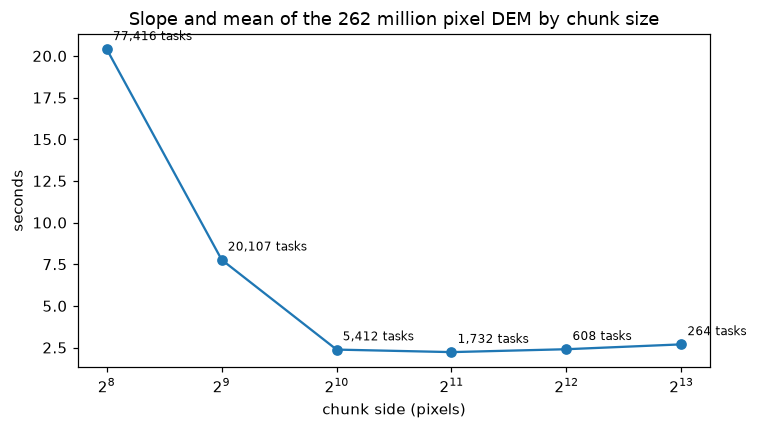

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))  # one panel
ax.plot(chunks.index, chunks.seconds, "o-")  # time against chunk side
for c, r in chunks.iterrows():  # label each point
    ax.annotate(f"{r.tasks:,.0f} tasks", (c, r.seconds), textcoords="offset points", xytext=(4, 6), fontsize=8)  # task count
ax.set_xscale("log", base=2); ax.set_xlabel("chunk side (pixels)"); ax.set_ylabel("seconds")  # axes
ax.set_title("Slope and mean of the 262 million pixel DEM by chunk size"); plt.tight_layout(); plt.show()  # draw

The 256 pixel chunks (0.26 MB each) created 77,000 tasks and took about nine times longer
than the best setting. In this run 2048 pixel chunks (17 MB) were fastest, with 4096 (67 MB) close
behind, and 8192 pixel chunks slowed down again because six chunks cannot keep 24 threads busy.
The best size is somewhat below the 100 MB rule of thumb here because slope does little work per
pixel and smaller chunks stay in the CPU caches; for heavier work per pixel the optimum moves up. Measuring a few sizes, as here, takes a
minute and is worth it for any job that will run for hours.

## Persist, compute and pulling results

- `.compute()` (or `pdist.compute`) runs the graph and **returns the result to the client**.
- `pdist.persist(x)` runs the graph and **keeps the result in worker memory**, returning a lazy
  handle to it. Later computations start from there instead of re-reading the files.
- `.values` and `np.asarray` on a lazy array compute it and copy everything to the client: fine
  for a summary, costly for a gigabyte.

In [13]:
s = pdist.start("local", n_workers=4, threads_per_worker=6, memory_limit="24GB")  # a fresh cluster
t = {}  # seconds per step
with dd.timer("slope and aspect from the files (two reads)", t):  # without persist
    float(pdist.raster.slope(dem, compute="cpu").mean()); float(pdist.raster.aspect(dem, compute="cpu").mean())  # each reads the DEM
with dd.timer("persist the DEM in worker memory", t):  # keep it on the workers
    dem_p = pdist.persist(dem); from dask.distributed import wait; wait(dem_p.data)  # wait until loaded
with dd.timer("slope and aspect from the persisted DEM", t):  # reuse
    float(pdist.raster.slope(dem_p, compute="cpu").mean()); float(pdist.raster.aspect(dem_p, compute="cpu").mean())  # no file reads
with dd.timer("pull the full slope raster to the client (.values)", t):  # a gigabyte over the network
    arr = pdist.raster.slope(dem_p, compute="cpu").values  # computed and copied
print(f"pulled {dd.gb(arr.nbytes)}; client process now uses {dd.rss_gb():.1f} GB")  # what it cost
print(pdist.memory_report()["workers"])  # memory on each worker

slope and aspect from the files (two reads): 7.17 s


persist the DEM in worker memory: 0.62 s


slope and aspect from the persisted DEM: 4.74 s


pull the full slope raster to the client (.values): 2.70 s
pulled 1.05 GB; client process now uses 10.0 GB
{'tcp://127.0.0.1:38505': {'memory_gb': 1.751, 'limit_gb': 24.0}, 'tcp://127.0.0.1:40075': {'memory_gb': 1.503, 'limit_gb': 24.0}, 'tcp://127.0.0.1:42751': {'memory_gb': 1.339, 'limit_gb': 24.0}, 'tcp://127.0.0.1:44949': {'memory_gb': 1.262, 'limit_gb': 24.0}}


Persisting paid off as soon as the DEM was reused: the second pair of operations skipped the
GeoTIFF reads and decoding and ran about a third faster. Pulling the whole slope raster to the
client took 2.7 s, more than half the time of computing slope and aspect on the persisted DEM,
and all of it went into serializing every chunk and sending it from the worker processes to
this one. Keep large
results on the workers and bring back summaries, or write them to disk from the workers with
`pdist.write_raster` (notebook 02).

In [14]:
del dem_p, arr  # release worker and client memory
s.close()  # shut down

## A cluster script

Worker processes start by importing the main module. In a script, code at the top level would
run again in every worker, so cluster code must sit under `if __name__ == "__main__":`. (Notebooks
do not need the guard: their main module is the kernel.) The cell below writes such a script to
`scripts/slope_on_cluster.py` and runs it.

In [15]:
script = Path("scripts/slope_on_cluster.py")  # where the script goes
script.parent.mkdir(exist_ok=True)  # create the folder
script.write_text("""\
\"\"\"Slope of the Great Plains DEM on a local Dask cluster, written to Zarr.\"\"\"

import time
from pathlib import Path

import geolattice.distributed as pdist

ROOT = Path(__file__).resolve().parents[4]
DEM = ROOT / "Data" / "03_spatial_analysis" / "Great_plain" / "Raster" / "elev.tif"
OUT = Path(__file__).resolve().parents[1] / "outputs" / "gp_slope.zarr"


def main():
    with pdist.start("local", n_workers=4, threads_per_worker=6) as session:
        print("workers:", session.status()["workers"])
        t = time.perf_counter()
        dem = pdist.read_raster(DEM, chunks={"y": 2048, "x": 2048})
        slope = pdist.raster.slope(dem, compute="cpu")
        pdist.write_raster(slope, OUT)  # each worker writes its own chunks
        print(f"wrote {OUT.name} in {time.perf_counter() - t:.1f} s")


if __name__ == "__main__":  # worker processes import this file; only the parent runs main()
    main()
""")  # script text
r = subprocess.run([sys.executable, str(script)], capture_output=True, text=True)  # run it
print(r.stdout or r.stderr[-1500:])  # its output
z = pdist.read_zarr(OUT / "gp_slope.zarr")  # open the result lazily
print(z, "\nchunks:", z.slope.data.chunksize)  # same grid, written chunk by chunk

workers: 4
wrote gp_slope.zarr in 3.9 s

<xarray.Dataset> Size: 1GB
Dimensions:      (y: 17196, x: 15245)
Coordinates:
  * y            (y) float64 138kB 2.539e+06 2.539e+06 ... 9.92e+05 9.919e+05
  * x            (x) float64 122kB -1.25e+06 -1.25e+06 ... 1.216e+05 1.217e+05
Data variables:
    slope        (y, x) float32 1GB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    spatial_ref  int64 8B ... 
chunks: (2048, 2048)


In [16]:
import shutil  # file removal
shutil.rmtree(OUT / "gp_slope.zarr")  # remove the 1 GB result again

## Summary and exercises

- A Dask cluster has a client, a scheduler, workers and nannies; without one, Dask's threaded
  scheduler runs everything in this process on all cores.
- NumPy, GDAL and vectorized Shapely run in parallel on threads; pure Python loops need processes.
  Here 24 single-threaded processes ran a Python loop twice as fast as 24 threads, and a
  vectorized Shapely call was about twenty-five times faster again.
- For NumPy work on one machine the threaded scheduler beat the local cluster, which pays for
  moving halo strips between processes.
- `pdist.start` starts local, GPU, SLURM, PBS and Kubernetes clusters or joins a running one; the
  `Session` scales, adapts, reports status and closes, also as a context manager.
- Chunk size matters: tiny chunks drown in task overhead and huge ones leave cores idle; measure
  a few sizes for long jobs.
- `persist` keeps reused data in worker memory; `.values` copies everything to the client.
- Cluster scripts need the `if __name__ == "__main__":` guard.

**Exercises**

1. Repeat the threads and processes comparison with `pdist.vector.buffer(bld, 10)`. Which setup
   wins, and why?
2. Start a cluster with `memory_limit="1GB"` per worker and persist the DEM. Watch what the
   workers do (the dashboard, or `pdist.memory_report()`), and explain.
3. Write the PBS version of the SLURM job script with `pdist.start("pbs", ...)` and compare the
   two.
4. Add a `--workers` argument to `scripts/slope_on_cluster.py` and plot the run time for 1, 2, 4
   and 8 workers.